# A Hybrid Machine Learning Framework for Segment Classification and Price Prediction in the South African Used Car Market

**Binamra Thapa - ST10090477** | **Module:** RPDA8412 | **Supervisor:** Dr Moses Olaifa

This notebook runs the full analysis: data cleaning, clustering comparison, segment investigation, price prediction with tuning and repeated experiments, outlier sensitivity, feature importance, and the provincial analysis.

**How to run:** place the five CSV files in a `data/` folder next to this notebook, then choose Kernel → Restart & Run All.

**Run time:** most cells take seconds. The tuning cell in section 5.2 takes much longer and prints its progress.

## 1. Setup

In [1]:
%pip install xgboost lightgbm shap kmodes

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import sys
import time
import warnings
from itertools import combinations

import joblib
import lightgbm
import kmodes
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import shap
import sklearn
import xgboost

from kmodes.kprototypes import KPrototypes
from lightgbm import LGBMRegressor
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
np.random.seed(42)

DATA_FOLDER = "data"
CSV_FILES = [
    "wc_cars.csv",
    "cars_kzn_cars.csv",
    "kzn_cars_webuycars.csv",
    "carsco_cars.csv",
    "johannesburg_cars_webuy-cars.csv",
]

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy", scipy.__version__)
print("xgboost", xgboost.__version__)
print("lightgbm", lightgbm.__version__)
print("shap", shap.__version__)
print("kmodes", kmodes.__version__)

Python 3.11.16
pandas 3.0.6
numpy 2.4.6
scikit-learn 1.9.1
scipy 1.17.1
xgboost 3.2.0
lightgbm 4.7.0
shap 0.51.0
kmodes 0.12.2


/opt/anaconda3/envs/pdan8412/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data loading and cleaning

Prices are **advertised asking prices** in rand. The five files are combined, made consistent across platforms, deduplicated and cleaned. Records removed by the IQR filter are kept aside so that they can be examined.

In [3]:
COLUMNS_TO_KEEP = [
    "source", "make", "model", "variant", "price_zar", "year", "mileage_km", "transmission",
    "fuel_type", "colour", "body_type", "engine_cc", "seller_type", "suburb", "province", "listing_url",
]

PROVINCE_NAMES = {
    "kwazulu-natal": "KwaZulu-Natal",
    "kwazulu natal": "KwaZulu-Natal",
    "kzn": "KwaZulu-Natal",
    "gauteng": "Gauteng",
    "western cape": "Western Cape",
}


def clean_province(text):
    """Give each province one standard spelling."""
    return PROVINCE_NAMES.get(text, text.title())


def clean_engine_size(value):
    """Convert engine size to cc. Values under 20 are in litres, for example 1.6 becomes 1600."""
    if pd.isna(value):
        return np.nan
    match = re.search(r"[\d.]+", str(value).strip().lower())
    if not match:
        return np.nan
    number = float(match.group())
    if number < 20:
        return round(number * 1000)
    return round(number)


# Load the five files and combine them
frames = []
for file_name in CSV_FILES:
    data = pd.read_csv(os.path.join(DATA_FOLDER, file_name))
    for column in COLUMNS_TO_KEEP:
        if column not in data.columns:
            data[column] = np.nan
    frames.append(data[COLUMNS_TO_KEEP])
raw = pd.concat(frames, ignore_index=True)
count_raw = len(raw)

# Make the values consistent across the two platforms
raw["engine_cc"] = raw["engine_cc"].apply(clean_engine_size)
raw["province"] = raw["province"].astype(str).str.strip().str.lower().map(clean_province)
raw["suburb"] = raw["suburb"].astype(str).str.replace(r"\s*\((GP|KZN|WC)\)\s*", "", regex=True).str.strip()
for column in ["transmission", "fuel_type", "seller_type"]:
    raw[column] = raw[column].astype(str).str.strip().str.title().replace({"Nan": np.nan})
raw["make"] = raw["make"].astype(str).str.strip().replace({"nan": np.nan, "Nan": np.nan})
raw_counts = pd.crosstab(raw["source"], raw["province"], margins=True)

# Remove duplicates: the same URL, or the same car details listed twice
raw = raw.drop_duplicates(subset=["listing_url"])
raw = raw.drop_duplicates(subset=["make", "model", "variant", "price_zar", "year", "mileage_km", "province"])
count_after_duplicates = len(raw)

# Remove incomplete records and anything outside the three provinces
raw = raw.dropna(subset=["price_zar", "mileage_km", "year", "make", "province"])
raw = raw[raw["province"].isin(["Gauteng", "KwaZulu-Natal", "Western Cape"])]
count_after_incomplete = len(raw)

# Remove impossible values
raw = raw[raw["price_zar"].between(20000, 5000000)]
raw = raw[raw["mileage_km"].between(0, 500000)]
raw = raw[raw["year"].between(1990, 2026)]
count_after_bounds = len(raw)
before_iqr = raw.copy()


def iqr_limits(values):
    """Return the lower and upper limits of the IQR rule."""
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def within_iqr_limits(values):
    """True for values inside the IQR limits."""
    lower, upper = iqr_limits(values)
    return values.between(lower, upper)


def prepare_for_modelling(data):
    """Fill missing values and add the age and log-price columns."""
    data = data.copy()
    for column in ["transmission", "fuel_type", "colour", "body_type", "seller_type"]:
        if data[column].isna().any():
            data[column] = data[column].fillna(data[column].mode().iloc[0])
    data["engine_cc"] = data["engine_cc"].fillna(data["engine_cc"].median())
    data["variant"] = data["variant"].fillna("Unknown")
    data["age"] = 2026 - data["year"]
    data["log_price"] = np.log10(data["price_zar"])
    return data.reset_index(drop=True)


# Apply the IQR rule to price and mileage, keeping the removed records aside
keep = within_iqr_limits(before_iqr["price_zar"]) & within_iqr_limits(before_iqr["mileage_km"])
removed = before_iqr[~keep].copy()
df = prepare_for_modelling(before_iqr[keep])
df_without_iqr = prepare_for_modelling(before_iqr)

print(f"Combined raw listings: {count_raw:,}")
print(f"After duplicate removal: {count_after_duplicates:,}")
print(f"After removing incomplete or out-of-scope records: {count_after_incomplete:,}")
print(f"After sanity bounds: {count_after_bounds:,}")
print(f"After IQR outlier removal (final): {len(df):,}")
print("\nRaw records by platform and province:")
print(raw_counts)
print("\nFinal records by platform and province:")
print(pd.crosstab(df["source"], df["province"], margins=True))

Combined raw listings: 4,783
After duplicate removal: 4,699
After removing incomplete or out-of-scope records: 4,699
After sanity bounds: 4,694
After IQR outlier removal (final): 4,232

Raw records by platform and province:
province    Gauteng  KwaZulu-Natal  Western Cape   All
source                                                
Cars.co.za     1076           1149          1150  3375
WeBuyCars       465            472           471  1408
All            1541           1621          1621  4783

Final records by platform and province:
province    Gauteng  KwaZulu-Natal  Western Cape   All
source                                                
Cars.co.za      927            982           965  2874
WeBuyCars       438            467           453  1358
All            1365           1449          1418  4232


### 2.1 Characteristics of the removed outliers

In [4]:
LUXURY_MAKES = ["Mercedes-Benz", "BMW", "Audi", "Land Rover", "Jaguar", "Porsche", "Lexus", "Volvo"]

price_lower, price_upper = iqr_limits(before_iqr["price_zar"])
mileage_lower, mileage_upper = iqr_limits(before_iqr["mileage_km"])
high_price = removed[removed["price_zar"] > price_upper]
high_mileage = removed[removed["mileage_km"] > mileage_upper]
both = (removed["price_zar"] > price_upper) & (removed["mileage_km"] > mileage_upper)

print(f"Removed by IQR: {len(removed)} ({len(removed) / len(before_iqr):.1%} of the data)")
print(f"Price limits: R{price_lower:,.0f} to R{price_upper:,.0f}")
print(f"Mileage limits: {mileage_lower:,.0f} to {mileage_upper:,.0f} km")
print(f"\nRemoved for high price: {len(high_price)}")
print(f"  of which luxury makes: {high_price['make'].isin(LUXURY_MAKES).sum()}")
print(f"Removed for low price: {(removed['price_zar'] < price_lower).sum()}")
print(f"Removed for high mileage: {len(high_mileage)}")
print(f"  median mileage: {high_mileage['mileage_km'].median():,.0f} km")
print(f"  median price: R{high_mileage['price_zar'].median():,.0f}")
print(f"Removed for both: {both.sum()}")
print(f"\nAll removed records: median price R{removed['price_zar'].median():,.0f}, maximum R{removed['price_zar'].max():,.0f}")
print(f"Luxury vehicles removed: {removed['make'].isin(LUXURY_MAKES).sum()}")
print("Luxury removed by make:", removed[removed["make"].isin(LUXURY_MAKES)]["make"].value_counts().to_dict())
print("Removed by platform:", removed["source"].value_counts().to_dict())
print("Removed by province:", removed["province"].value_counts().to_dict())
print("\nTop makes removed:")
print(removed["make"].value_counts().head(6))

Removed by IQR: 462 (9.8% of the data)
Price limits: R-162,288 to R764,412
Mileage limits: -98,630 to 222,378 km

Removed for high price: 367
  of which luxury makes: 148
Removed for low price: 0
Removed for high mileage: 95
  median mileage: 259,000 km
  median price: R199,900
Removed for both: 0

All removed records: median price R899,900, maximum R3,449,990
Luxury vehicles removed: 159
Luxury removed by make: {'BMW': 77, 'Mercedes-Benz': 33, 'Land Rover': 23, 'Porsche': 14, 'Lexus': 5, 'Volvo': 3, 'Jaguar': 2, 'Audi': 2}
Removed by platform: {'Cars.co.za': 413, 'WeBuyCars': 49}
Removed by province: {'Gauteng': 161, 'Western Cape': 159, 'KwaZulu-Natal': 142}

Top makes removed:
make
Toyota           118
BMW               77
Ford              69
Mercedes-Benz     33
Volkswagen        29
Land Rover        23
Name: count, dtype: int64


## 3. Phase 1: comparison of clustering algorithms

K-Means, K-Prototypes, Hierarchical and DBSCAN are compared on the segmentation features (excluding price, make and model) using three validation indices. K-Prototypes handles categories natively, so it also checks the one-hot encoding used by K-Means.

In [5]:
NUMERIC_FEATURES = ["year", "mileage_km", "engine_cc", "age"]
SEGMENT_CATEGORIES = ["transmission", "fuel_type", "body_type", "province"]


def make_cluster_encoder(categories):
    """Standardise the numbers and one-hot encode the categories."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categories),
    ])


def to_dense(matrix):
    """Convert a sparse matrix to a normal array."""
    if hasattr(matrix, "toarray"):
        return matrix.toarray()
    return matrix


def score_clusters(features, labels):
    """Return the three validation indices, ignoring DBSCAN noise points (label -1)."""
    clusters = set(labels) - {-1}
    if len(clusters) < 2:
        note = f"collapsed ({len(clusters)} cluster, {(labels == -1).sum()} noise)"
        return {"silhouette": None, "db": None, "ch": None, "note": note}
    not_noise = labels != -1
    return {
        "silhouette": round(silhouette_score(features[not_noise], labels[not_noise]), 3),
        "db": round(davies_bouldin_score(features[not_noise], labels[not_noise]), 3),
        "ch": round(calinski_harabasz_score(features[not_noise], labels[not_noise]), 0),
        "note": "",
    }


encoder = make_cluster_encoder(SEGMENT_CATEGORIES)
X = to_dense(encoder.fit_transform(df))

kmeans_labels = KMeans(2, random_state=42, n_init=10).fit_predict(X)
hierarchical_labels = AgglomerativeClustering(2).fit_predict(X)
dbscan_labels = DBSCAN(eps=2.0, min_samples=10).fit_predict(X)

# K-Prototypes works on the original categories, not the one-hot columns
kprototypes_data = df[NUMERIC_FEATURES + SEGMENT_CATEGORIES].copy()
for column in NUMERIC_FEATURES:
    kprototypes_data[column] = (kprototypes_data[column] - kprototypes_data[column].mean()) / kprototypes_data[column].std()
category_positions = [kprototypes_data.columns.get_loc(column) for column in SEGMENT_CATEGORIES]
kprototypes_model = KPrototypes(n_clusters=2, random_state=42, n_init=3, verbose=0)
kprototypes_labels = kprototypes_model.fit_predict(kprototypes_data.values, categorical=category_positions)

comparison = pd.DataFrame({
    "K-Means": score_clusters(X, np.array(kmeans_labels)),
    "K-Prototypes": score_clusters(X, np.array(kprototypes_labels)),
    "Hierarchical": score_clusters(X, np.array(hierarchical_labels)),
    "DBSCAN": score_clusters(X, np.array(dbscan_labels)),
}).T
print(comparison)

             silhouette     db      ch                             note
K-Means           0.297  1.418  1886.0                                 
K-Prototypes      0.296  1.418  1882.0                                 
Hierarchical      0.199  1.701  1255.0                                 
DBSCAN              NaN    NaN     NaN  collapsed (1 cluster, 32 noise)


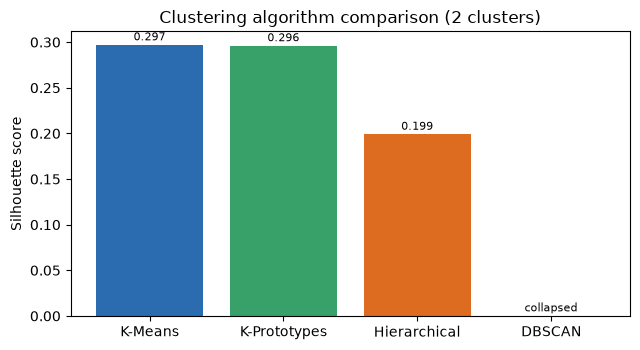

In [6]:
# Figure: silhouette score of each algorithm (DBSCAN collapsed, so it has no score)
names = list(comparison.index)
scores = []
for name in names:
    value = comparison.loc[name, "silhouette"]
    if pd.isna(value):
        scores.append(0)
    else:
        scores.append(float(value))

plt.figure(figsize=(6.5, 3.6))
bars = plt.bar(names, scores, color=["#2b6cb0", "#38a169", "#dd6b20", "#a0aec0"])
for bar, score in zip(bars, scores):
    label = f"{score:.3f}" if score else "collapsed"
    plt.text(bar.get_x() + bar.get_width() / 2, score + 0.005, label, ha="center", fontsize=8)
plt.ylabel("Silhouette score")
plt.title("Clustering algorithm comparison (2 clusters)")
plt.tight_layout()
plt.show()

In [7]:
# Stability check 1: repeat K-Means on 80% samples (without replacement)
reference_labels = KMeans(2, random_state=42, n_init=10).fit_predict(X)
subsample_ari = []
for run in range(20):
    rows = np.random.choice(len(X), int(0.8 * len(X)), replace=False)
    labels = KMeans(2, random_state=1000 + run, n_init=10).fit_predict(X[rows])
    subsample_ari.append(adjusted_rand_score(reference_labels[rows], labels))
print(f"80% subsampling (20 runs): mean ARI {np.mean(subsample_ari):.3f}, sd {np.std(subsample_ari):.3f}, "
      f"min {np.min(subsample_ari):.3f}, max {np.max(subsample_ari):.3f}")

# Stability check 2: a true bootstrap, drawing rows with replacement
generator = np.random.default_rng(42)
bootstrap_ari = []
bootstrap_silhouette = []
for run in range(50):
    rows = generator.integers(0, len(X), len(X))
    labels = KMeans(2, random_state=2000 + run, n_init=10).fit_predict(X[rows])
    bootstrap_ari.append(adjusted_rand_score(reference_labels[rows], labels))
    bootstrap_silhouette.append(silhouette_score(X[rows], labels, sample_size=2000, random_state=run))
print(f"True bootstrap (50 resamples): ARI mean {np.mean(bootstrap_ari):.3f}, "
      f"95% interval {np.percentile(bootstrap_ari, 2.5):.3f} to {np.percentile(bootstrap_ari, 97.5):.3f}")
print(f"True bootstrap silhouette: mean {np.mean(bootstrap_silhouette):.3f}, "
      f"95% interval {np.percentile(bootstrap_silhouette, 2.5):.3f} to {np.percentile(bootstrap_silhouette, 97.5):.3f}")

# Name the segments: the cluster with the lower median price is Budget
df["cluster"] = kmeans_labels
median_prices = df.groupby("cluster")["price_zar"].median().sort_values()
cheaper_cluster = median_prices.index[0]
dearer_cluster = median_prices.index[1]
df["segment"] = df["cluster"].map({cheaper_cluster: "Budget", dearer_cluster: "Premium"})

80% subsampling (20 runs): mean ARI 0.990, sd 0.007, min 0.975, max 0.998
True bootstrap (50 resamples): ARI mean 0.982, 95% interval 0.958 to 0.996
True bootstrap silhouette: mean 0.299, 95% interval 0.290 to 0.310


### 3.1 How many clusters, and does including brand help? (RQ2)

K-Means is run for k = 2 to 8 under two configurations. **Experiment 1** includes make and model. **Experiment 2** excludes them. The elbow and the three validation indices are reported together.

                        experiment  k  inertia  silhouette    db   ch
   Experiment 1 (with make, model)  2    26286       0.232 1.699 1334
   Experiment 1 (with make, model)  3    23593       0.190 1.823  984
   Experiment 1 (with make, model)  4    22087       0.142 1.922  797
   Experiment 1 (with make, model)  5    20979       0.110 2.236  685
   Experiment 1 (with make, model)  6    19961       0.110 2.178  619
   Experiment 1 (with make, model)  7    19364       0.107 2.250  553
   Experiment 1 (with make, model)  8    18844       0.099 2.289  504
Experiment 2 (without make, model)  2    18451       0.297 1.418 1886
Experiment 2 (without make, model)  3    15842       0.255 1.501 1446
Experiment 2 (without make, model)  4    14368       0.202 1.556 1208
Experiment 2 (without make, model)  5    13278       0.192 1.582 1066
Experiment 2 (without make, model)  6    12283       0.170 1.679  991
Experiment 2 (without make, model)  7    11721       0.170 1.715  899
Experiment 2 (withou

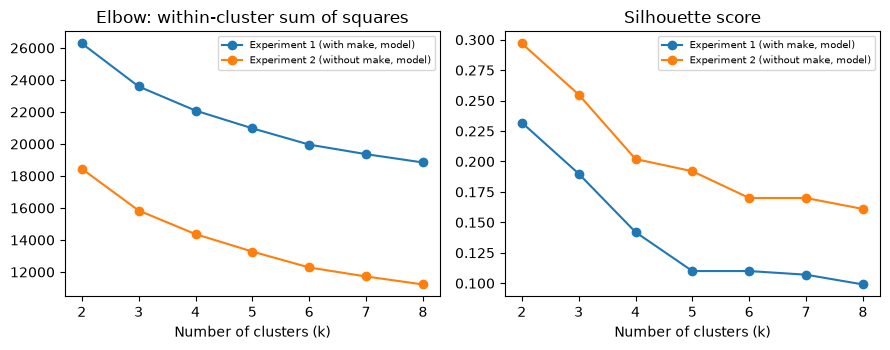

In [8]:
EXPERIMENT_1 = "Experiment 1 (with make, model)"
EXPERIMENT_2 = "Experiment 2 (without make, model)"

brand_encoder = make_cluster_encoder(SEGMENT_CATEGORIES + ["make", "model"])
X_with_brand = to_dense(brand_encoder.fit_transform(df))

rows = []
all_cluster_labels = {}
for experiment, features in [(EXPERIMENT_1, X_with_brand), (EXPERIMENT_2, X)]:
    for k in range(2, 9):
        model = KMeans(k, random_state=42, n_init=10).fit(features)
        all_cluster_labels[(experiment, k)] = model.labels_
        rows.append({
            "experiment": experiment,
            "k": k,
            "inertia": round(model.inertia_),
            "silhouette": round(silhouette_score(features, model.labels_), 3),
            "db": round(davies_bouldin_score(features, model.labels_), 3),
            "ch": round(calinski_harabasz_score(features, model.labels_)),
        })
k_results = pd.DataFrame(rows)
print(k_results.to_string(index=False))

figure, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for experiment, group in k_results.groupby("experiment"):
    axes[0].plot(group["k"], group["inertia"], marker="o", label=experiment)
    axes[1].plot(group["k"], group["silhouette"], marker="o", label=experiment)
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[1].set_title("Silhouette score")
for axis in axes:
    axis.set_xlabel("Number of clusters (k)")
    axis.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.2 What would more clusters, or brand-aware clusters, look like?

This tests whether finer or brand-aware clusters would capture market prestige, rather than only age.

In [9]:
TOP_LUXURY_MAKES = ["Mercedes-Benz", "BMW", "Audi"]


def describe_clusters(labels):
    """Summarise each cluster, ordered from the lowest to the highest median price."""
    data = df.assign(cluster_number=labels)
    order = data.groupby("cluster_number")["price_zar"].median().sort_values().index
    rows = []
    for position, cluster in enumerate(order):
        group = data[data["cluster_number"] == cluster]
        rows.append({
            "cluster": position + 1,
            "n": len(group),
            "price_median": group["price_zar"].median(),
            "age_median": group["age"].median(),
            "mileage_median": group["mileage_km"].median(),
            "lux_share": round(group["make"].isin(TOP_LUXURY_MAKES).mean(), 3),
            "top_makes": ", ".join(group["make"].value_counts().head(3).index),
        })
    return pd.DataFrame(rows).to_string(index=False)


for experiment, k in [(EXPERIMENT_2, 3), (EXPERIMENT_2, 4), (EXPERIMENT_1, 2), (EXPERIMENT_1, 4)]:
    print(f"\n{experiment}, k={k}:")
    print(describe_clusters(all_cluster_labels[(experiment, k)]))


Experiment 2 (without make, model), k=3:
 cluster    n  price_median  age_median  mileage_median  lux_share                  top_makes
       1 1104      137400.0        10.0        121023.5      0.147  Volkswagen, Ford, Hyundai
       2 2201      259950.0         2.0         29453.0      0.030 Volkswagen, Suzuki, Toyota
       3  927      439900.0         4.0         73500.0      0.121          Toyota, Ford, BMW

Experiment 2 (without make, model), k=4:
 cluster    n  price_median  age_median  mileage_median  lux_share                       top_makes
       1  602      129990.0        12.0        141505.0      0.238 Volkswagen, Mercedes-Benz, Ford
       2  943      169990.0         7.0         92037.0      0.055       Volkswagen, Ford, Hyundai
       3 1819      278500.0         2.0         23950.0      0.028      Suzuki, Volkswagen, Toyota
       4  868      459900.0         4.0         68000.0      0.109        Toyota, Ford, Volkswagen

Experiment 1 (with make, model), k=2:
 clust

## 4. Phase 1: market segment investigation

Is the segmentation a genuine market-tier split, or does it mainly separate newer from older vehicles?

In [10]:
SEGMENTS = ["Budget", "Premium"]

rows = []
for segment in SEGMENTS:
    group = df[df["segment"] == segment]
    rows.append({
        "segment": segment,
        "n": len(group),
        "price_median": group["price_zar"].median(),
        "price_cv": round(group["price_zar"].std() / group["price_zar"].mean(), 3),
        "mileage_median": group["mileage_km"].median(),
        "age_median": group["age"].median(),
        "age_min": group["age"].min(),
        "age_max": group["age"].max(),
        "makes": group["make"].nunique(),
        "lux_share": round(group["make"].isin(TOP_LUXURY_MAKES).mean(), 3),
        "top_makes": ", ".join(group["make"].value_counts().head(3).index),
    })
print(pd.DataFrame(rows).set_index("segment").T)

print("\nYoung cars (3 years or younger) by segment:")
print(df[df["age"] <= 3]["segment"].value_counts())

for segment in SEGMENTS:
    count = df[(df["segment"] == segment) & df["make"].isin(TOP_LUXURY_MAKES)].shape[0]
    print(f"Mercedes-Benz, BMW and Audi in {segment}: {count}")

segment                           Budget                     Premium
n                                   1468                        2764
price_median                    164999.0                    289620.0
price_cv                           0.661                       0.443
mileage_median                  120835.0                     32978.0
age_median                           9.0                         2.0
age_min                                1                           0
age_max                               36                           9
makes                                 45                          54
lux_share                          0.146                       0.046
top_makes       Ford, Volkswagen, Toyota  Toyota, Volkswagen, Suzuki

Young cars (3 years or younger) by segment:
segment
Premium    1852
Budget       15
Name: count, dtype: int64
Mercedes-Benz, BMW and Audi in Budget: 214
Mercedes-Benz, BMW and Audi in Premium: 127


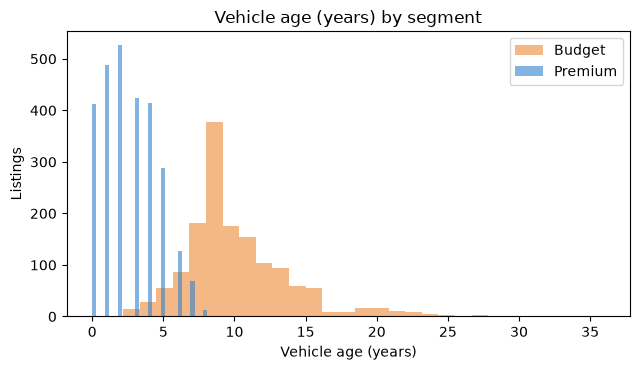

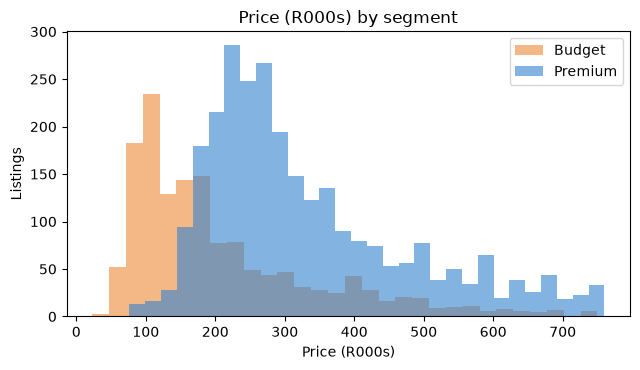

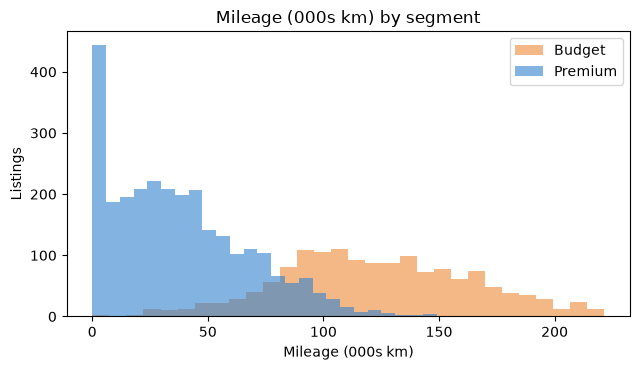

In [11]:
SEGMENT_COLOURS = {"Budget": "#ed8936", "Premium": "#3182ce"}

for column, label, divide_by in [
    ("age", "Vehicle age (years)", 1),
    ("price_zar", "Price (R000s)", 1000),
    ("mileage_km", "Mileage (000s km)", 1000),
]:
    plt.figure(figsize=(6.5, 3.8))
    for segment in SEGMENTS:
        values = df[df["segment"] == segment][column] / divide_by
        plt.hist(values, bins=30, alpha=0.6, label=segment, color=SEGMENT_COLOURS[segment])
    plt.xlabel(label)
    plt.ylabel("Listings")
    plt.legend()
    plt.title(f"{label} by segment")
    plt.tight_layout()
    plt.show()

### 4.1 Composition of the two segments in depth

Which brands dominate each segment? Did clustering make the segments homogeneous in age and mileage? How much variation does the split explain, and do brands still differ inside a segment?

segment              Budget     Premium
n                  1468.000    2764.000
price_median     164999.000  289620.000
price_q1         108275.000  225900.000
price_q3         268625.000  399990.000
price_cv              0.661       0.443
log_price_sd          0.259       0.182
mileage_median   120835.000   32978.000
mileage_q1        93741.500   13717.750
mileage_q3       152000.000   56000.000
mileage_cv            0.336       0.781
age_median            9.000       2.000
age_q1                7.000       1.000
age_q3               12.000       4.000
age_sd                3.820       1.900
makes                45.000      54.000
models              275.000     265.000
top3_make_share       0.388       0.420
top5_make_share       0.546       0.579
effective_makes      19.100      18.900
hhi                   0.076       0.083

Top 8 makes in each segment (share of that segment):
  Budget: Ford 13.4%, Volkswagen 13.1%, Toyota 12.3%, Hyundai 9.3%, Mercedes-Benz 6.5%, Nissan 5.8%, BMW 5

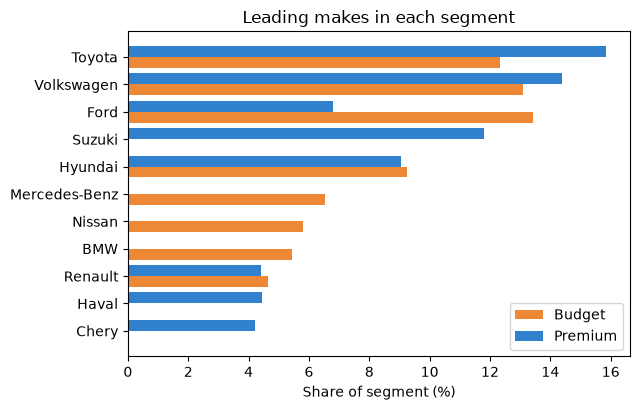

In [12]:
def coefficient_of_variation(values):
    return values.std() / values.mean()


def variance_explained(values, groups):
    """Eta squared: the share of the variance explained by the groups."""
    overall_mean = values.mean()
    between = 0
    for _, group in values.groupby(groups):
        between += len(group) * (group.mean() - overall_mean) ** 2
    total = ((values - overall_mean) ** 2).sum()
    return between / total


rows = []
for segment in SEGMENTS:
    group = df[df["segment"] == segment]
    make_shares = group["make"].value_counts(normalize=True)
    rows.append({
        "segment": segment,
        "n": len(group),
        "price_median": group["price_zar"].median(),
        "price_q1": group["price_zar"].quantile(0.25),
        "price_q3": group["price_zar"].quantile(0.75),
        "price_cv": round(coefficient_of_variation(group["price_zar"]), 3),
        "log_price_sd": round(group["log_price"].std(), 3),
        "mileage_median": group["mileage_km"].median(),
        "mileage_q1": group["mileage_km"].quantile(0.25),
        "mileage_q3": group["mileage_km"].quantile(0.75),
        "mileage_cv": round(coefficient_of_variation(group["mileage_km"]), 3),
        "age_median": group["age"].median(),
        "age_q1": group["age"].quantile(0.25),
        "age_q3": group["age"].quantile(0.75),
        "age_sd": round(group["age"].std(), 2),
        "makes": group["make"].nunique(),
        "models": group["model"].nunique(),
        "top3_make_share": round(make_shares.head(3).sum(), 3),
        "top5_make_share": round(make_shares.head(5).sum(), 3),
        "effective_makes": round(float(np.exp(-(make_shares * np.log(make_shares)).sum())), 1),
        "hhi": round(float((make_shares ** 2).sum()), 3),
    })
print(pd.DataFrame(rows).set_index("segment").T.to_string())

print("\nTop 8 makes in each segment (share of that segment):")
for segment in SEGMENTS:
    shares = df[df["segment"] == segment]["make"].value_counts(normalize=True).head(8)
    text = ", ".join(f"{make} {share:.1%}" for make, share in shares.items())
    print(f"  {segment}: {text}")

print("\nShare of variance explained by the segment split (eta squared):")
for column in ["age", "mileage_km", "log_price", "engine_cc"]:
    print(f"  {column}: {variance_explained(df[column], df['segment']):.3f}")

print("\nStandard deviation overall and inside each segment:")
for column in ["age", "mileage_km", "log_price"]:
    budget_sd = df[df["segment"] == "Budget"][column].std()
    premium_sd = df[df["segment"] == "Premium"][column].std()
    print(f"  {column}: overall {df[column].std():,.2f} | Budget {budget_sd:,.2f} | Premium {premium_sd:,.2f}")

print("\nDoes brand still separate prices inside a segment? Eta squared of make on log price:")
for segment in SEGMENTS:
    group = df[df["segment"] == segment]
    print(f"  {segment}: {variance_explained(group['log_price'], group['make']):.3f}")

print("\nSame age, different market position: cars aged 3 years or younger")
young = df[df["age"] <= 3]
rows = []
for make in ["Suzuki", "Toyota", "Volkswagen", "Mercedes-Benz", "BMW", "Audi"]:
    group = young[young["make"] == make]
    rows.append({
        "make": make,
        "n": len(group),
        "premium_share": round((group["segment"] == "Premium").mean(), 3),
        "price_median": group["price_zar"].median(),
        "age_median": group["age"].median(),
    })
print(pd.DataFrame(rows).sort_values("price_median").to_string(index=False))

AGE_BANDS = [-1, 3, 6, 9, 15, 40]
AGE_BAND_NAMES = ["0-3", "4-6", "7-9", "10-15", "16+"]
print("\nSegment membership by age band:")
print(pd.crosstab(pd.cut(df["age"], AGE_BANDS, labels=AGE_BAND_NAMES), df["segment"]).to_string())

# Figure: leading makes in each segment
top_makes = pd.concat([
    df[df["segment"] == "Budget"]["make"].value_counts(normalize=True).head(8).rename("Budget"),
    df[df["segment"] == "Premium"]["make"].value_counts(normalize=True).head(8).rename("Premium"),
], axis=1).fillna(0)
top_makes = top_makes.loc[top_makes.max(axis=1).sort_values().index]
positions = np.arange(len(top_makes))
plt.figure(figsize=(6.5, 4.2))
plt.barh(positions - 0.2, top_makes["Budget"] * 100, 0.4, label="Budget", color=SEGMENT_COLOURS["Budget"])
plt.barh(positions + 0.2, top_makes["Premium"] * 100, 0.4, label="Premium", color=SEGMENT_COLOURS["Premium"])
plt.yticks(positions, top_makes.index)
plt.xlabel("Share of segment (%)")
plt.title("Leading makes in each segment")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Phase 2: price prediction

Within each split, the scaler, encoder and centroids are fitted on the **training data only**. Test vehicles are assigned to the nearest centroid, as a new listing would be. Models are trained per segment, and predictions are converted from log10 back to rand (10 to the power of the prediction) before RMSE, MAE and MAPE are calculated.

In [13]:
MODEL_CATEGORIES = ["make", "model", "transmission", "fuel_type", "body_type", "colour", "province", "seller_type"]
MODEL_FEATURES = NUMERIC_FEATURES + MODEL_CATEGORIES


def mean_absolute_percentage_error(actual, predicted):
    return float(np.mean(np.abs((actual - predicted) / actual)) * 100)


def make_preprocessor():
    """One-hot encode the categories and keep the numbers.

    sparse_threshold=0 keeps the data dense, so XGBoost reads a 0 as a real zero and not as missing.
    """
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), MODEL_CATEGORIES)],
        remainder="passthrough",
        sparse_threshold=0,
    )


def make_default_models():
    """The four models with one fixed set of settings."""
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=250, max_depth=18, n_jobs=-1, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=350, learning_rate=0.05, max_depth=6, subsample=0.9,
                                colsample_bytree=0.9, random_state=42, n_jobs=-1, verbosity=0),
        "LightGBM": LGBMRegressor(n_estimators=350, learning_rate=0.05, num_leaves=31,
                                  n_jobs=-1, random_state=42, verbose=-1),
    }


def assign_segments(train, test):
    """Fit the clustering on the training data only, then assign test vehicles to the nearest centroid."""
    encoder = make_cluster_encoder(SEGMENT_CATEGORIES)
    X_train = to_dense(encoder.fit_transform(train))
    kmeans = KMeans(2, random_state=42, n_init=10).fit(X_train)
    X_test = to_dense(encoder.transform(test))

    train = train.copy()
    test = test.copy()
    train["cluster_id"] = kmeans.labels_
    test["cluster_id"] = kmeans.predict(X_test)

    medians = train.groupby("cluster_id")["price_zar"].median().sort_values()
    names = {medians.index[0]: "Budget", medians.index[1]: "Premium"}
    train["segment"] = train["cluster_id"].map(names)
    test["segment"] = test["cluster_id"].map(names)
    return train, test


def run_fixed_models(data, seed=42):
    """One train-test split, with all four models trained per segment using fixed settings."""
    train, test = train_test_split(data, test_size=0.2, random_state=seed, stratify=data["province"])
    train, test = assign_segments(train, test)
    rows = []
    for segment in SEGMENTS:
        segment_train = train[train["segment"] == segment]
        segment_test = test[test["segment"] == segment]
        if len(segment_test) < 10:
            continue
        for name, model in make_default_models().items():
            pipeline = Pipeline([("pre", make_preprocessor()), ("model", model)])
            pipeline.fit(segment_train[MODEL_FEATURES], segment_train["log_price"])
            predicted = 10 ** pipeline.predict(segment_test[MODEL_FEATURES])
            actual = segment_test["price_zar"].values
            rows.append({
                "segment": segment,
                "model": name,
                "R2": round(r2_score(segment_test["log_price"], np.log10(predicted)), 3),
                "RMSE": round(np.sqrt(mean_squared_error(actual, predicted))),
                "MAE": round(mean_absolute_error(actual, predicted)),
                "MAPE": round(mean_absolute_percentage_error(actual, predicted), 1),
            })
    return pd.DataFrame(rows)


print(run_fixed_models(df, 42).to_string(index=False))

segment             model    R2  RMSE   MAE  MAPE
 Budget Linear Regression 0.829 69128 40306  18.5
 Budget     Random Forest 0.852 60214 37278  17.7
 Budget           XGBoost 0.892 51986 32168  15.2
 Budget          LightGBM 0.875 56213 34090  15.9
Premium Linear Regression 0.857 59303 36770  11.1
Premium     Random Forest 0.849 58119 36299  11.2
Premium           XGBoost 0.871 53619 34437  10.6
Premium          LightGBM 0.854 55517 35758  11.3


### 5.1 Repeated experiments (10 runs) with one fixed configuration

In [14]:
all_runs = []
for seed in range(10):
    all_runs.append(run_fixed_models(df, 100 + seed))
all_runs = pd.concat(all_runs)

rows = []
for (segment, name), group in all_runs.groupby(["segment", "model"]):
    rows.append({
        "segment": segment,
        "model": name,
        "R2_mean": round(group["R2"].mean(), 3),
        "R2_std": round(group["R2"].std(ddof=0), 3),
    })
fixed_summary = pd.DataFrame(rows).sort_values(["segment", "R2_mean"], ascending=[True, False])
print(fixed_summary.to_string(index=False))

segment             model  R2_mean  R2_std
 Budget           XGBoost    0.852   0.018
 Budget          LightGBM    0.829   0.022
 Budget     Random Forest    0.816   0.023
 Budget Linear Regression    0.815   0.022
Premium           XGBoost    0.878   0.013
Premium Linear Regression    0.863   0.015
Premium          LightGBM    0.858   0.015
Premium     Random Forest    0.853   0.017


### 5.2 Hyperparameter tuning inside each repeated experiment

For each of the ten train-test splits, each ensemble model is tuned with a randomised search and 5-fold cross-validation on the **training data of that segment only**, optimising RMSE on the log-price. The test set is never used for tuning. A global XGBoost model is tuned and tested on the same splits, so the two approaches are compared on the same vehicles.

**This cell takes a while.** Each finished split is saved in `tuning_cache/`, so if it stops, run it again and it continues where it left off. Delete that folder to start from scratch.

In [15]:
SEARCH_ITERATIONS = 12
CV_FOLDS = 5
SEEDS = list(range(100, 110))

SEARCH_SPACES = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [10, 14, 18, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.33, 0.5],
    },
    "XGBoost": {
        "model__n_estimators": [300, 500, 800],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_depth": [3, 4, 6, 8],
        "model__subsample": [0.7, 0.9, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1, 3],
    },
    "LightGBM": {
        "model__n_estimators": [300, 500, 800],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__num_leaves": [15, 31, 63],
        "model__min_child_samples": [5, 10, 20],
        "model__subsample": [0.7, 0.9, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
    },
}


def make_untuned_model(name):
    if name == "Linear Regression":
        return LinearRegression()
    if name == "Random Forest":
        return RandomForestRegressor(n_jobs=1, random_state=42)
    if name == "XGBoost":
        return XGBRegressor(random_state=42, n_jobs=1, verbosity=0)
    return LGBMRegressor(random_state=42, n_jobs=1, verbose=-1, subsample_freq=1)


def fit_model(name, features, target, seed):
    """Fit one model. Linear Regression has nothing to tune, and the others use a randomised search."""
    pipeline = Pipeline([("pre", make_preprocessor()), ("model", make_untuned_model(name))])
    if name not in SEARCH_SPACES:
        pipeline.fit(features, target)
        return pipeline, {}

    search = RandomizedSearchCV(
        pipeline,
        SEARCH_SPACES[name],
        n_iter=SEARCH_ITERATIONS,
        cv=KFold(CV_FOLDS, shuffle=True, random_state=seed),
        scoring="neg_root_mean_squared_error",
        random_state=seed,
        n_jobs=-1,
        refit=True,
    )
    search.fit(features, target)
    best_settings = {}
    for setting, value in search.best_params_.items():
        best_settings[setting.replace("model__", "")] = value
    return search.best_estimator_, best_settings


def run_tuned_split(seed):
    """Tune and test every model on one train-test split, and save the result."""
    cache_path = f"tuning_cache/iter{SEARCH_ITERATIONS}_seed{seed}.joblib"
    if os.path.exists(cache_path):
        return joblib.load(cache_path)

    train, test = train_test_split(df, test_size=0.2, random_state=seed, stratify=df["province"])
    train, test = assign_segments(train, test)
    columns = ["source", "make", "province", "segment", "price_zar", "log_price", "age", "mileage_km"]
    predictions = test[columns].copy()
    best_settings = {}

    # Segment-aware models
    for segment in SEGMENTS:
        segment_train = train[train["segment"] == segment]
        segment_test = test[test["segment"] == segment]
        for name in ["Linear Regression", "Random Forest", "XGBoost", "LightGBM"]:
            model, settings = fit_model(name, segment_train[MODEL_FEATURES], segment_train["log_price"], seed)
            predictions.loc[segment_test.index, name] = 10 ** model.predict(segment_test[MODEL_FEATURES])
            best_settings[(segment, name)] = settings

    # Global model, trained on all the training data
    model, settings = fit_model("XGBoost", train[MODEL_FEATURES], train["log_price"], seed)
    predictions["Global XGBoost"] = 10 ** model.predict(test[MODEL_FEATURES])
    best_settings[("Global", "XGBoost")] = settings

    result = {"seed": seed, "predictions": predictions, "best_settings": best_settings}
    os.makedirs("tuning_cache", exist_ok=True)
    joblib.dump(result, cache_path)
    return result


start_time = time.time()
tuned_results = []
for position, seed in enumerate(SEEDS):
    tuned_results.append(run_tuned_split(seed))
    minutes = (time.time() - start_time) / 60
    print(f"split {position + 1}/{len(SEEDS)} done, {minutes:.1f} min so far", flush=True)

split 1/10 done, 0.0 min so far
split 2/10 done, 0.0 min so far
split 3/10 done, 0.0 min so far
split 4/10 done, 0.0 min so far
split 5/10 done, 0.0 min so far
split 6/10 done, 0.0 min so far
split 7/10 done, 0.0 min so far
split 8/10 done, 0.0 min so far
split 9/10 done, 0.0 min so far
split 10/10 done, 0.0 min so far


### 5.3 Tuned results: all metrics in rand, with variation across the ten splits

segment             model  R2_mean  R2_sd  R2_min  R2_max  R2_ci_low  R2_ci_high  RMSE_mean  RMSE_sd  MAE_mean  MAE_sd  MAPE_mean  MAPE_sd
 Budget          LightGBM    0.848  0.021   0.819   0.874      0.832       0.863      52862     3389     33208    2425       17.7      1.4
 Budget           XGBoost    0.848  0.021   0.815   0.875      0.833       0.864      53336     3993     33021    2241       17.4      1.3
 Budget     Random Forest    0.823  0.028   0.771   0.870      0.803       0.843      57164     4911     36312    2662       19.2      1.6
 Budget Linear Regression    0.815  0.023   0.787   0.852      0.799       0.832      61174     4945     37919    2497       19.5      1.6
Premium           XGBoost    0.886  0.015   0.858   0.916      0.875       0.897      52935     2432     33540    1112        9.9      0.3
Premium          LightGBM    0.883  0.017   0.848   0.912      0.871       0.895      52861     2844     33775     789       10.0      0.3
Premium Linear Regression  

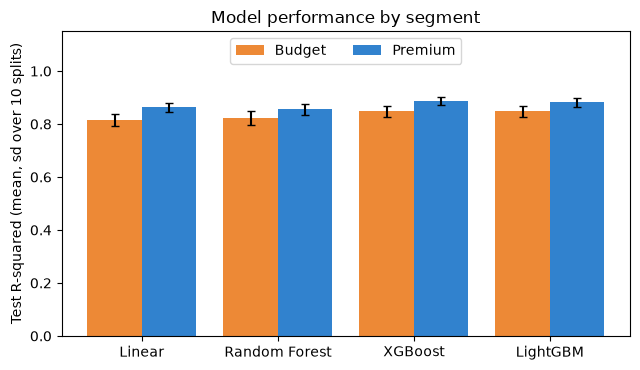

In [16]:
MODEL_NAMES = ["Linear Regression", "Random Forest", "XGBoost", "LightGBM"]


def score_predictions(predictions, column):
    actual = predictions["price_zar"].values
    predicted = predictions[column].values
    return {
        "R2": r2_score(predictions["log_price"], np.log10(predicted)),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": mean_absolute_percentage_error(actual, predicted),
    }


def confidence_interval_95(values):
    values = np.asarray(values)
    margin = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean() - margin, values.mean() + margin


# One row for each split, segment and model
rows = []
for result in tuned_results:
    for segment in SEGMENTS:
        segment_predictions = result["predictions"][result["predictions"]["segment"] == segment]
        for name in MODEL_NAMES:
            scores = score_predictions(segment_predictions, name)
            rows.append({"seed": result["seed"], "segment": segment, "model": name, **scores})
split_scores = pd.DataFrame(rows)

# Summary table
rows = []
for (segment, name), group in split_scores.groupby(["segment", "model"]):
    low, high = confidence_interval_95(group["R2"])
    rows.append({
        "segment": segment,
        "model": name,
        "R2_mean": round(group["R2"].mean(), 3),
        "R2_sd": round(group["R2"].std(ddof=1), 3),
        "R2_min": round(group["R2"].min(), 3),
        "R2_max": round(group["R2"].max(), 3),
        "R2_ci_low": round(low, 3),
        "R2_ci_high": round(high, 3),
        "RMSE_mean": round(group["RMSE"].mean()),
        "RMSE_sd": round(group["RMSE"].std(ddof=1)),
        "MAE_mean": round(group["MAE"].mean()),
        "MAE_sd": round(group["MAE"].std(ddof=1)),
        "MAPE_mean": round(group["MAPE"].mean(), 1),
        "MAPE_sd": round(group["MAPE"].std(ddof=1), 1),
    })
tuned_summary = pd.DataFrame(rows).sort_values(["segment", "R2_mean"], ascending=[True, False])
print(tuned_summary.to_string(index=False))

print("\nHow often each model had the highest R-squared, out of ten splits:")
best_rows = split_scores.loc[split_scores.groupby(["seed", "segment"])["R2"].idxmax()]
print(best_rows.groupby(["segment", "model"]).size().unstack(fill_value=0).to_string())

print("\nPaired difference in R-squared between the best model and each other model, per split:")
for segment in SEGMENTS:
    table = split_scores[split_scores["segment"] == segment].pivot(index="seed", columns="model", values="R2")
    best_model = table.mean().idxmax()
    for name in table.columns.drop(best_model):
        difference = table[best_model] - table[name]
        low, high = confidence_interval_95(difference)
        t_value, p_value = stats.ttest_rel(table[best_model], table[name])
        print(f"  {segment}: {best_model} minus {name}: mean {difference.mean():.3f}, sd {difference.std(ddof=1):.3f}, "
              f"95% CI {low:.3f} to {high:.3f}, wins {(difference > 0).sum()}/10, paired t p={p_value:.3g}")
print("\nThe splits share data, so these intervals are descriptive and slightly narrow rather than exact tests.")

print("\nBest settings chosen in the first split:")
for key, settings in tuned_results[0]["best_settings"].items():
    print(" ", key, settings)

# Figure: mean R-squared by model and segment, with standard deviation error bars
means = split_scores.groupby(["model", "segment"])["R2"].agg(["mean", "std"]).reset_index()
positions = np.arange(len(MODEL_NAMES))
plt.figure(figsize=(6.5, 3.8))
for offset, segment in [(-0.2, "Budget"), (0.2, "Premium")]:
    segment_means = means[means["segment"] == segment].set_index("model").loc[MODEL_NAMES]
    plt.bar(positions + offset, segment_means["mean"], 0.4, yerr=segment_means["std"], capsize=3,
            label=segment, color=SEGMENT_COLOURS[segment])
plt.xticks(positions, ["Linear", "Random Forest", "XGBoost", "LightGBM"])
plt.ylabel("Test R-squared (mean, sd over 10 splits)")
plt.ylim(0, 1.15)
plt.title("Model performance by segment")
plt.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

### 5.4 Segment-aware versus global model

Both are scored on all the test vehicles in the same ten splits.

In [17]:
rows = []
for result in tuned_results:
    rows.append({"seed": result["seed"], "approach": "Segment-aware XGBoost", **score_predictions(result["predictions"], "XGBoost")})
    rows.append({"seed": result["seed"], "approach": "Global XGBoost", **score_predictions(result["predictions"], "Global XGBoost")})
approach_scores = pd.DataFrame(rows)
print(approach_scores.groupby("approach")[["R2", "RMSE", "MAE", "MAPE"]].agg(["mean", "std"]).round(3).T.to_string())

r2_table = approach_scores.pivot(index="seed", columns="approach", values="R2")
r2_difference = r2_table["Segment-aware XGBoost"] - r2_table["Global XGBoost"]
low, high = confidence_interval_95(r2_difference)
print(f"\nSegment-aware minus global R-squared: mean {r2_difference.mean():.4f}, 95% CI {low:.4f} to {high:.4f}, "
      f"segment-aware higher in {(r2_difference > 0).sum()}/10 splits")

mape_table = approach_scores.pivot(index="seed", columns="approach", values="MAPE")
mape_difference = mape_table["Segment-aware XGBoost"] - mape_table["Global XGBoost"]
low, high = confidence_interval_95(mape_difference)
print(f"Segment-aware minus global MAPE: mean {mape_difference.mean():.3f} points, 95% CI {low:.3f} to {high:.3f}")

print("\nGlobal model scored inside each segment, for comparison with the segment models:")
rows = []
for result in tuned_results:
    for segment in SEGMENTS:
        segment_predictions = result["predictions"][result["predictions"]["segment"] == segment]
        rows.append({"segment": segment, **score_predictions(segment_predictions, "Global XGBoost")})
print(pd.DataFrame(rows).groupby("segment")[["R2", "MAPE"]].mean().round(3).to_string())

approach   Global XGBoost  Segment-aware XGBoost
R2   mean           0.905                  0.897
     std            0.007                  0.008
RMSE mean       50650.946              53169.687
     std         1527.963               1639.745
MAE  mean       32171.995              33377.021
     std          948.802               1072.974
MAPE mean          12.045                 12.503
     std            0.466                  0.596

Segment-aware minus global R-squared: mean -0.0083, 95% CI -0.0103 to -0.0062, segment-aware higher in 0/10 splits
Segment-aware minus global MAPE: mean 0.458 points, 95% CI 0.312 to 0.604

Global model scored inside each segment, for comparison with the segment models:
            R2    MAPE
segment               
Budget   0.861  16.690
Premium  0.895   9.598


### 5.5 Residuals, and why one segment is easier to predict

R-squared compares the unexplained variation with the total variation, so a segment with a wider price spread can score a higher R-squared even when its errors are larger. Both parts are therefore shown. Residuals are pooled across the ten splits for the tuned XGBoost models.

segment              Budget  Premium
total_sd_log_price   0.2606   0.1845
residual_sd_log      0.1014   0.0622
residual_mean_log   -0.0008   0.0007
unexplained_share    0.1510   0.1140
skew                -0.3400  -0.2600
kurtosis             4.1600   8.7500
median_abs_pct      12.0000   6.9000
mean_abs_pct        17.5000   9.9000
within_10pct         0.4320   0.6510
within_20pct         0.7010   0.8860
over_50pct           0.0500   0.0120

MAPE by age band and segment:
                  size  mean
segment age_band            
Budget  0-3         22  16.8
        4-6        366  13.9
        7-9       1100  14.6
        10-15     1227  19.1
        16+        187  31.0
Premium 0-3       3770   9.3
        4-6       1619  11.2
        7-9        179  11.2

MAPE and signed error by platform and segment:
                       n   MAPE  mean_signed_error_pct
segment source                                        
Budget  Cars.co.za  1657  17.77                   3.13
        WeBuyCars   12

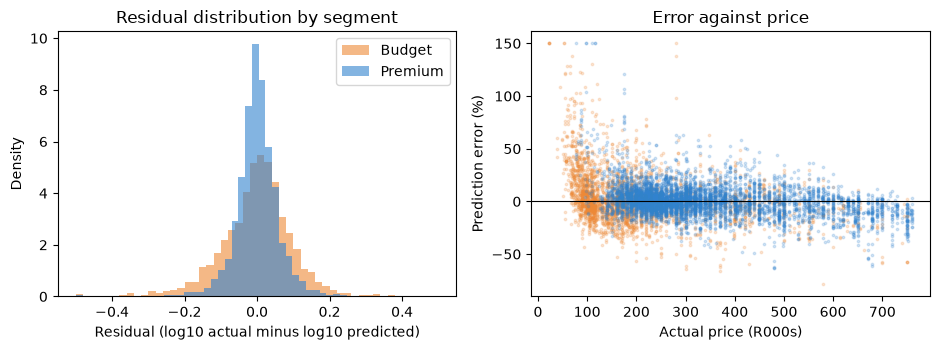

In [18]:
pooled = pd.concat([result["predictions"].assign(seed=result["seed"]) for result in tuned_results])
pooled["residual_log"] = pooled["log_price"] - np.log10(pooled["XGBoost"])
pooled["error_pct"] = (pooled["XGBoost"] - pooled["price_zar"]) / pooled["price_zar"] * 100
pooled["abs_error_pct"] = pooled["error_pct"].abs()

rows = []
for segment in SEGMENTS:
    group = pooled[pooled["segment"] == segment]
    rows.append({
        "segment": segment,
        "total_sd_log_price": round(group["log_price"].std(), 4),
        "residual_sd_log": round(group["residual_log"].std(), 4),
        "residual_mean_log": round(group["residual_log"].mean(), 4),
        "unexplained_share": round((group["residual_log"] ** 2).mean() / group["log_price"].var(), 3),
        "skew": round(stats.skew(group["residual_log"]), 2),
        "kurtosis": round(stats.kurtosis(group["residual_log"]), 2),
        "median_abs_pct": round(group["abs_error_pct"].median(), 1),
        "mean_abs_pct": round(group["abs_error_pct"].mean(), 1),
        "within_10pct": round((group["abs_error_pct"] <= 10).mean(), 3),
        "within_20pct": round((group["abs_error_pct"] <= 20).mean(), 3),
        "over_50pct": round((group["abs_error_pct"] > 50).mean(), 3),
    })
print(pd.DataFrame(rows).set_index("segment").T.to_string())

pooled["age_band"] = pd.cut(pooled["age"], AGE_BANDS, labels=AGE_BAND_NAMES)
print("\nMAPE by age band and segment:")
print(pooled.groupby(["segment", "age_band"], observed=True)["abs_error_pct"].agg(["size", "mean"]).round(1).to_string())

print("\nMAPE and signed error by platform and segment:")
print(pooled.groupby(["segment", "source"]).agg(
    n=("abs_error_pct", "size"),
    MAPE=("abs_error_pct", "mean"),
    mean_signed_error_pct=("error_pct", "mean"),
).round(2).to_string())

pooled["price_band"] = pd.cut(pooled["price_zar"], [0, 100000, 200000, 300000, 450000, 1e8],
                              labels=["<100k", "100-200k", "200-300k", "300-450k", ">450k"])
print("\nMAPE by price band and segment:")
print(pooled.groupby(["segment", "price_band"], observed=True)["abs_error_pct"].agg(["size", "mean"]).round(1).to_string())

figure, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for segment in SEGMENTS:
    group = pooled[pooled["segment"] == segment]
    colour = SEGMENT_COLOURS[segment]
    axes[0].hist(group["residual_log"].clip(-0.5, 0.5), bins=50, alpha=0.6, density=True, label=segment, color=colour)
    axes[1].scatter(group["price_zar"] / 1000, group["error_pct"].clip(-100, 150), s=3, alpha=0.2, label=segment, color=colour)
axes[0].set_xlabel("Residual (log10 actual minus log10 predicted)")
axes[0].set_ylabel("Density")
axes[0].set_title("Residual distribution by segment")
axes[0].legend()
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Actual price (R000s)")
axes[1].set_ylabel("Prediction error (%)")
axes[1].set_title("Error against price")
plt.tight_layout()
plt.show()

### 5.6 Sensitivity to outlier removal

All four models are run with the same ten random seeds, with and without the IQR filter, using one fixed configuration so that only the data changes. XGBoost models trained without the filter are also scored on the extreme vehicles themselves.

In [19]:
results_with_iqr = []
results_without_iqr = []
for seed in SEEDS:
    results_with_iqr.append(run_fixed_models(df, seed).assign(config="With IQR removal"))
    results_without_iqr.append(run_fixed_models(df_without_iqr, seed).assign(config="Without IQR removal"))
sensitivity = pd.concat(results_with_iqr + results_without_iqr)
print(sensitivity.groupby(["config", "segment", "model"])[["R2", "MAPE"]].agg(["mean", "std"]).round(3).to_string())

print("\nBest model by mean R-squared in each configuration:")
sensitivity_means = sensitivity.groupby(["config", "segment", "model"])["R2"].mean().reset_index()
print(sensitivity_means.sort_values("R2").groupby(["config", "segment"]).tail(1).to_string(index=False))

# Score the extreme vehicles separately
flagged = before_iqr.copy()
flagged["extreme"] = ~keep
flagged = prepare_for_modelling(flagged)
rows = []
for seed in SEEDS:
    train, test = train_test_split(flagged, test_size=0.2, random_state=seed, stratify=flagged["province"])
    train, test = assign_segments(train, test)
    for segment in SEGMENTS:
        segment_train = train[train["segment"] == segment]
        segment_test = test[test["segment"] == segment]
        pipeline = Pipeline([("pre", make_preprocessor()), ("model", make_default_models()["XGBoost"])])
        pipeline.fit(segment_train[MODEL_FEATURES], segment_train["log_price"])
        test.loc[segment_test.index, "predicted"] = 10 ** pipeline.predict(segment_test[MODEL_FEATURES])
    for label, group in [("extreme vehicles", test[test["extreme"]]), ("all other vehicles", test[~test["extreme"]])]:
        percent_errors = np.abs(group["predicted"] - group["price_zar"]) / group["price_zar"]
        rows.append({
            "group": label,
            "n": len(group),
            "R2": r2_score(group["log_price"], np.log10(group["predicted"])),
            "MAPE": mean_absolute_percentage_error(group["price_zar"].values, group["predicted"].values),
            "median_ape": float(np.median(percent_errors) * 100),
        })
print("\nXGBoost trained without the IQR filter, scored separately on each group of test vehicles:")
print(pd.DataFrame(rows).groupby("group")[["n", "R2", "MAPE", "median_ape"]].mean().round(3).to_string())

                                                  R2          MAPE       
                                                mean    std   mean    std
config              segment model                                        
With IQR removal    Budget  LightGBM           0.829  0.023  18.86  1.612
                            Linear Regression  0.815  0.023  19.51  1.584
                            Random Forest      0.816  0.024  19.66  1.472
                            XGBoost            0.852  0.019  17.51  1.264
                    Premium LightGBM           0.858  0.016  11.41  0.463
                            Linear Regression  0.863  0.016  11.02  0.193
                            Random Forest      0.853  0.018  11.43  0.609
                            XGBoost            0.878  0.014  10.35  0.280
Without IQR removal Budget  LightGBM           0.787  0.024  21.09  1.157
                            Linear Regression  0.786  0.031  21.64  1.269
                            Random For

## 6. Feature importance for each segment

The tuned XGBoost model for each segment is refitted on the training data of each split and explained on that split's unseen test vehicles. One-hot columns are added together **for each vehicle** before taking the absolute value, because adding up every dummy column separately would inflate features with many categories, such as colour. Year and age are the same information (age = 2026 - year), so they are combined.

Permutation importance is a second, independent check. It shuffles one feature in the test set and records how far R-squared falls.


Budget: average over ten splits
              mean_abs_shap   share  share_sd  r2_drop_permutation
feature                                                           
Age / year           0.0788  0.1973    0.0077               0.3236
Engine size          0.0775  0.1943    0.0312               0.2072
Seller Type          0.0468  0.1172    0.0061               0.0898
Make                 0.0437  0.1091    0.0127               0.1085
Transmission         0.0388  0.0974    0.0118               0.0543
Mileage              0.0312  0.0781    0.0045               0.0644
Fuel Type            0.0281  0.0706    0.0218               0.0298
Body Type            0.0273  0.0684    0.0076               0.0430
Model                0.0127  0.0317    0.0073               0.0167
Province             0.0084  0.0209    0.0038               0.0047
Colour               0.0060  0.0149    0.0041               0.0001
Top feature by split: {'Age / year': 5, 'Engine size': 5}


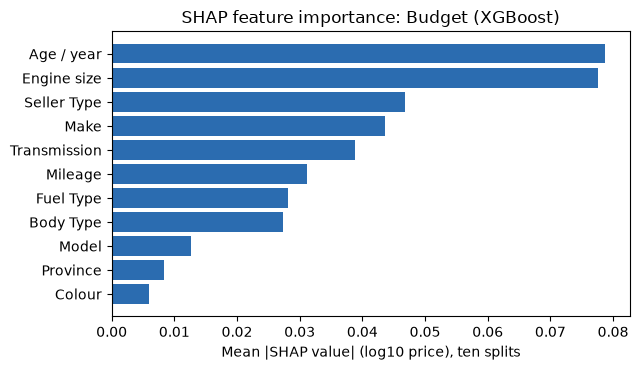


Premium: average over ten splits
              mean_abs_shap   share  share_sd  r2_drop_permutation
feature                                                           
Engine size          0.0454  0.1659    0.0114               0.1856
Transmission         0.0401  0.1465    0.0111               0.1061
Make                 0.0370  0.1350    0.0081               0.2467
Fuel Type            0.0331  0.1209    0.0143               0.1191
Age / year           0.0286  0.1043    0.0027               0.0845
Body Type            0.0285  0.1042    0.0061               0.0812
Model                0.0258  0.0941    0.0077               0.1158
Mileage              0.0198  0.0724    0.0032               0.0489
Seller Type          0.0083  0.0304    0.0063               0.0117
Colour               0.0038  0.0139    0.0028               0.0038
Province             0.0034  0.0124    0.0019               0.0002
Top feature by split: {'Engine size': 9, 'Transmission': 1}


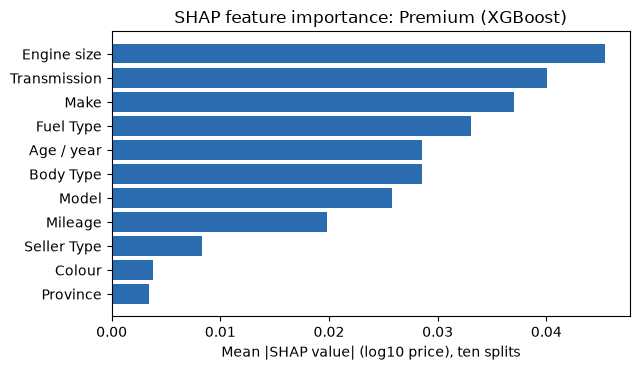

In [20]:
FEATURE_GROUPS = {
    "Make": ["make"],
    "Model": ["model"],
    "Age / year": ["year", "age"],
    "Mileage": ["mileage_km"],
    "Engine size": ["engine_cc"],
    "Transmission": ["transmission"],
    "Fuel Type": ["fuel_type"],
    "Body Type": ["body_type"],
    "Colour": ["colour"],
    "Province": ["province"],
    "Seller Type": ["seller_type"],
}


def feature_group(column_name):
    """Find which original feature an encoded column belongs to."""
    for category in MODEL_CATEGORIES:
        if column_name.startswith(category + "_"):
            return category.replace("_", " ").title()
    if column_name in ["year", "age"]:
        return "Age / year"
    if column_name == "mileage_km":
        return "Mileage"
    return "Engine size"


shap_rows = []
permutation_rows = []
for result in tuned_results:
    seed = result["seed"]
    train, test = train_test_split(df, test_size=0.2, random_state=seed, stratify=df["province"])
    train, test = assign_segments(train, test)
    generator = np.random.default_rng(seed)

    for segment in SEGMENTS:
        segment_train = train[train["segment"] == segment]
        segment_test = test[test["segment"] == segment]

        preprocessor = make_preprocessor()
        X_train = preprocessor.fit_transform(segment_train[MODEL_FEATURES])
        column_names = []
        for name in preprocessor.get_feature_names_out():
            column_names.append(name.replace("cat__", "").replace("remainder__", ""))

        settings = result["best_settings"][(segment, "XGBoost")]
        model = XGBRegressor(random_state=42, n_jobs=-1, verbosity=0, **settings)
        model.fit(X_train, segment_train["log_price"].values)
        X_test = preprocessor.transform(segment_test[MODEL_FEATURES])

        # SHAP: add the columns of each feature together for each vehicle, then average the absolute values
        shap_values = pd.DataFrame(shap.TreeExplainer(model).shap_values(X_test), columns=column_names)
        importance = shap_values.T.groupby(feature_group).sum().T.abs().mean()
        for feature, value in importance.items():
            shap_rows.append({"seed": seed, "segment": segment, "feature": feature,
                              "mean_abs_shap": value, "share": value / importance.sum()})

        # Permutation: shuffle one feature in the test set and see how far R-squared falls
        baseline_r2 = r2_score(segment_test["log_price"], model.predict(X_test))
        for feature, columns in FEATURE_GROUPS.items():
            drops = []
            for repeat in range(3):
                shuffled = segment_test[MODEL_FEATURES].copy()
                order = generator.permutation(len(shuffled))
                shuffled[columns] = shuffled[columns].values[order]
                shuffled_r2 = r2_score(segment_test["log_price"], model.predict(preprocessor.transform(shuffled)))
                drops.append(baseline_r2 - shuffled_r2)
            permutation_rows.append({"seed": seed, "segment": segment, "feature": feature, "r2_drop": np.mean(drops)})

shap_table = pd.DataFrame(shap_rows)
permutation_table = pd.DataFrame(permutation_rows)

for segment in SEGMENTS:
    segment_shap = shap_table[shap_table["segment"] == segment]
    table = segment_shap.groupby("feature").agg(
        mean_abs_shap=("mean_abs_shap", "mean"),
        share=("share", "mean"),
        share_sd=("share", "std"),
    )
    segment_permutation = permutation_table[permutation_table["segment"] == segment]
    table["r2_drop_permutation"] = segment_permutation.groupby("feature")["r2_drop"].mean()
    table = table.sort_values("share", ascending=False)
    print(f"\n{segment}: average over ten splits")
    print(table.round(4).to_string())

    top_features = segment_shap.loc[segment_shap.groupby("seed")["share"].idxmax()]["feature"].value_counts().to_dict()
    print("Top feature by split:", top_features)

    chart_values = table["mean_abs_shap"][::-1]
    plt.figure(figsize=(6.5, 3.8))
    plt.barh(range(len(chart_values)), chart_values.values, color="#2b6cb0")
    plt.yticks(range(len(chart_values)), chart_values.index)
    plt.xlabel("Mean |SHAP value| (log10 price), ten splits")
    plt.title(f"SHAP feature importance: {segment} (XGBoost)")
    plt.tight_layout()
    plt.show()

## 7. Provincial analysis (RQ4)

Gauteng         n=1365 mean=R286,146 median=R249,900
KwaZulu-Natal   n=1449 mean=R282,595 median=R249,900
Western Cape    n=1418 mean=R300,652 median=R259,900

Levene W=18.562 p=9.413e-09
ANOVA F=5.391 p=0.004587
Kruskal-Wallis H=9.285 p=0.009631

Pairwise Mann-Whitney tests, Bonferroni corrected:
  Gauteng vs KwaZulu-Natal: p=0.9659 (not significant)
  Gauteng vs Western Cape: p=0.01392 (significant)
  KwaZulu-Natal vs Western Cape: p=0.07587 (not significant)

Shapiro-Wilk normality test on price:
  Gauteng: W=0.921, p=3.36e-26
  KwaZulu-Natal: W=0.917, p=1.7e-27
  Western Cape: W=0.935, p=2.61e-24

Effect sizes: eta squared 0.0025 | epsilon squared 0.0022
Western Cape minus Gauteng: mean R14,506, median R10,000


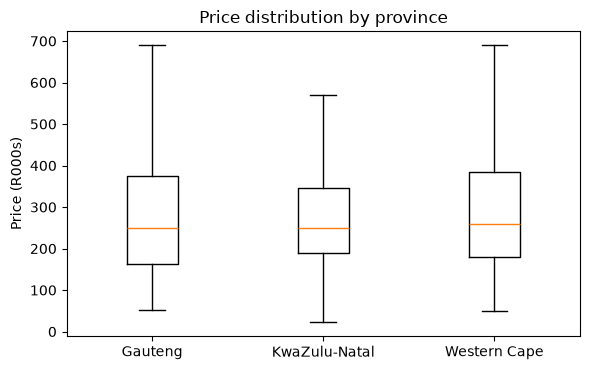


Prediction error by province, tuned XGBoost, across the ten splits:
                  n   MAPE  median_ape  mean_signed_error_pct
province                                                     
Gauteng        2730  13.86        8.82                   2.36
KwaZulu-Natal  2900  12.10        8.30                   1.09
Western Cape   2840  11.61        7.71                   1.53
Kruskal-Wallis on absolute % error, first split only (each vehicle counted once): H=2.808, p=0.246


In [21]:
PROVINCES = ["Gauteng", "KwaZulu-Natal", "Western Cape"]
prices = {}
for province in PROVINCES:
    prices[province] = df[df["province"] == province]["price_zar"].values
    values = prices[province]
    print(f"{province:15s} n={len(values):4d} mean=R{values.mean():,.0f} median=R{np.median(values):,.0f}")

gauteng, kzn, western_cape = prices["Gauteng"], prices["KwaZulu-Natal"], prices["Western Cape"]
levene_w, levene_p = stats.levene(gauteng, kzn, western_cape)
anova_f, anova_p = stats.f_oneway(gauteng, kzn, western_cape)
kruskal_h, kruskal_p = stats.kruskal(gauteng, kzn, western_cape)
print(f"\nLevene W={levene_w:.3f} p={levene_p:.4g}")
print(f"ANOVA F={anova_f:.3f} p={anova_p:.4g}")
print(f"Kruskal-Wallis H={kruskal_h:.3f} p={kruskal_p:.4g}")

# Pairwise tests with a Bonferroni correction
pairs = list(combinations(PROVINCES, 2))
print("\nPairwise Mann-Whitney tests, Bonferroni corrected:")
for first, second in pairs:
    u_value, p_value = stats.mannwhitneyu(prices[first], prices[second], alternative="two-sided")
    corrected = min(p_value * len(pairs), 1)
    result = "significant" if corrected < 0.05 else "not significant"
    print(f"  {first} vs {second}: p={corrected:.4g} ({result})")

print("\nShapiro-Wilk normality test on price:")
for province in PROVINCES:
    w_value, p_value = stats.shapiro(prices[province])
    print(f"  {province}: W={w_value:.3f}, p={p_value:.3g}")

# Effect sizes: how large is the difference, not only whether it exists?
overall_mean = df["price_zar"].mean()
between = 0
for province in PROVINCES:
    between += len(prices[province]) * (prices[province].mean() - overall_mean) ** 2
total = ((df["price_zar"] - overall_mean) ** 2).sum()
print(f"\nEffect sizes: eta squared {between / total:.4f} | epsilon squared {kruskal_h / (len(df) - 1):.4f}")
print(f"Western Cape minus Gauteng: mean R{western_cape.mean() - gauteng.mean():,.0f}, "
      f"median R{np.median(western_cape) - np.median(gauteng):,.0f}")

plt.figure(figsize=(6, 3.8))
plt.boxplot([prices[province] / 1000 for province in PROVINCES], showfliers=False)
plt.xticks([1, 2, 3], PROVINCES)
plt.ylabel("Price (R000s)")
plt.title("Price distribution by province")
plt.tight_layout()
plt.show()

# Does prediction error differ by province?
print("\nPrediction error by province, tuned XGBoost, across the ten splits:")
print(pooled.groupby("province").agg(
    n=("abs_error_pct", "size"),
    MAPE=("abs_error_pct", "mean"),
    median_ape=("abs_error_pct", "median"),
    mean_signed_error_pct=("error_pct", "mean"),
).round(2).to_string())

first_split = tuned_results[0]["predictions"].copy()
first_split["abs_error_pct"] = (first_split["XGBoost"] - first_split["price_zar"]).abs() / first_split["price_zar"] * 100
error_groups = [first_split[first_split["province"] == province]["abs_error_pct"].values for province in PROVINCES]
error_h, error_p = stats.kruskal(*error_groups)
print(f"Kruskal-Wallis on absolute % error, first split only (each vehicle counted once): H={error_h:.3f}, p={error_p:.3g}")

## 8. Additional checks

These cells do not change any earlier result. They support specific statements in the report: how closely the clusterings agree, the seller and platform overlap, body types by segment, the LightGBM comparisons, and how much two modelling choices matter (year and age both entering the clustering, and body-type labels that differ between platforms).

In [22]:
# How closely do the two-cluster solutions agree?
print(f"K-Means vs K-Prototypes: ARI {adjusted_rand_score(kmeans_labels, kprototypes_labels):.3f}")
with_brand = all_cluster_labels[(EXPERIMENT_1, 2)]
without_brand = all_cluster_labels[(EXPERIMENT_2, 2)]
print(f"Experiment 1 vs Experiment 2 at k=2: ARI {adjusted_rand_score(with_brand, without_brand):.3f}")

print("\nSeller type by platform:")
print(pd.crosstab(df["source"], df["seller_type"]))

# The two platforms use different names for some body types
BODY_TYPE_NAMES = {
    "Sports Utility Vehicle (SUV)": "SUV",
    "Crossover (SUV)": "Crossover",
    "Double Cab": "Double Cab Bakkie",
    "Single Cab": "Single Cab Bakkie",
    "C/P - Coupe": "Coupe",
}
df_harmonised = df.copy()
df_harmonised["body_type"] = df_harmonised["body_type"].replace(BODY_TYPE_NAMES)

print("\nBody type labels that differ between platforms (final dataset):")
changed = df[df["body_type"].isin(BODY_TYPE_NAMES)]
print(changed.groupby(["source", "body_type"]).size().to_string())
print(f"Listings affected: {len(changed)} of {len(df)}")

print("\nBody types by segment, with the labels combined (share of segment):")
for segment in SEGMENTS:
    shares = df_harmonised[df_harmonised["segment"] == segment]["body_type"].value_counts(normalize=True).head(5)
    text = ", ".join(f"{name} {share:.1%}" for name, share in shares.items())
    print(f"  {segment}: {text}")

print("\nPaired comparison of tuned LightGBM with Random Forest and Linear Regression:")
for segment in SEGMENTS:
    table = split_scores[split_scores["segment"] == segment].pivot(index="seed", columns="model", values="R2")
    for name in ["Random Forest", "Linear Regression"]:
        difference = table["LightGBM"] - table[name]
        low, high = confidence_interval_95(difference)
        t_value, p_value = stats.ttest_rel(table["LightGBM"], table[name])
        print(f"  {segment}: LightGBM minus {name}: mean {difference.mean():.3f}, 95% CI {low:.3f} to {high:.3f}, "
              f"wins {(difference > 0).sum()}/{len(difference)}, p={p_value:.3g}")

K-Means vs K-Prototypes: ARI 0.959
Experiment 1 vs Experiment 2 at k=2: ARI 0.990

Seller type by platform:
seller_type  Agent  Dealer  Person
source                            
Cars.co.za    2871       0       3
WeBuyCars        0    1358       0

Body type labels that differ between platforms (final dataset):
source     body_type                   
WeBuyCars  C/P - Coupe                       1
           Crossover (SUV)                  83
           Double Cab                        2
           Single Cab                       12
           Sports Utility Vehicle (SUV)    530
Listings affected: 628 of 4232

Body types by segment, with the labels combined (share of segment):
  Budget: Hatchback 36.9%, SUV 26.3%, Sedan 12.7%, Double Cab Bakkie 7.4%, Single Cab Bakkie 5.1%
  Premium: SUV 47.6%, Hatchback 30.4%, Double Cab Bakkie 6.4%, Sedan 5.1%, Single Cab Bakkie 3.1%

Paired comparison of tuned LightGBM with Random Forest and Linear Regression:
  Budget: LightGBM minus Random Fores

In [23]:
def describe_solution(data, labels, reference=None):
    """Print the variance explained by a two-cluster solution and the luxury share in each cluster."""
    print(f"  variance explained: age {variance_explained(data['age'], pd.Series(labels, index=data.index)):.3f}, "
          f"mileage {variance_explained(data['mileage_km'], pd.Series(labels, index=data.index)):.3f}, "
          f"log price {variance_explained(data['log_price'], pd.Series(labels, index=data.index)):.3f}")
    medians = data.assign(group=labels).groupby("group")["price_zar"].median().sort_values()
    for label, cluster in zip(["Lower-priced", "Higher-priced"], medians.index):
        group = data[labels == cluster]
        luxury = group["make"].isin(TOP_LUXURY_MAKES)
        print(f"  {label} cluster: n={len(group)}, median age {group['age'].median():.0f}, "
              f"Mercedes-Benz, BMW and Audi {luxury.sum()} ({luxury.mean():.1%})")


# Check 1: year and age are the same information, so age counts twice in the clustering. Remove year.
encoder_no_year = ColumnTransformer([
    ("num", StandardScaler(), ["mileage_km", "engine_cc", "age"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), SEGMENT_CATEGORIES),
])
X_no_year = to_dense(encoder_no_year.fit_transform(df))
labels_no_year = KMeans(2, random_state=42, n_init=10).fit_predict(X_no_year)
print("K-Means without year:")
print(f"  Silhouette {silhouette_score(X_no_year, labels_no_year):.3f}, "
      f"Davies-Bouldin {davies_bouldin_score(X_no_year, labels_no_year):.3f}, "
      f"Calinski-Harabasz {calinski_harabasz_score(X_no_year, labels_no_year):.0f}")
print(f"  ARI against the reported solution: {adjusted_rand_score(kmeans_labels, labels_no_year):.3f}")
describe_solution(df, labels_no_year)

# Check 2: combine the body type labels and repeat the clustering and fixed-configuration models
encoder_body = make_cluster_encoder(SEGMENT_CATEGORIES)
X_body = to_dense(encoder_body.fit_transform(df_harmonised))
labels_body = KMeans(2, random_state=42, n_init=10).fit_predict(X_body)
print("\nK-Means with body type labels combined:")
print(f"  Silhouette {silhouette_score(X_body, labels_body):.3f}, "
      f"Davies-Bouldin {davies_bouldin_score(X_body, labels_body):.3f}, "
      f"Calinski-Harabasz {calinski_harabasz_score(X_body, labels_body):.0f}")
print(f"  ARI against the reported solution: {adjusted_rand_score(kmeans_labels, labels_body):.3f}")

results_body = []
for seed in SEEDS:
    results_body.append(run_fixed_models(df_harmonised, seed))
results_body = pd.concat(results_body)
print("\nFixed-configuration R-squared with body type labels combined, same ten seeds:")
print(results_body.groupby(["segment", "model"])["R2"].mean().round(3).to_string())

# Check 3: where do luxury vehicles sit if the IQR filter is not applied?
encoder_all = make_cluster_encoder(SEGMENT_CATEGORIES)
X_all = to_dense(encoder_all.fit_transform(df_without_iqr))
labels_all = KMeans(2, random_state=42, n_init=10).fit_predict(X_all)
print("\nK-Means without the IQR filter:")
describe_solution(df_without_iqr, labels_all)

# Check 4: how many non-car listings remain?
print("\nMotorcycle makes in the final dataset:", df[df["make"].isin(["KTM", "Harley-Davidson", "Ducati", "Yamaha", "Kawasaki"])][["make", "model"]].value_counts().to_dict())

K-Means without year:
  Silhouette 0.250, Davies-Bouldin 1.650, Calinski-Harabasz 1447
  ARI against the reported solution: 0.797
  variance explained: age 0.545, mileage 0.635, log price 0.153
  Lower-priced cluster: n=1606, median age 9, Mercedes-Benz, BMW and Audi 227 (14.1%)
  Higher-priced cluster: n=2626, median age 2, Mercedes-Benz, BMW and Audi 114 (4.3%)

K-Means with body type labels combined:
  Silhouette 0.302, Davies-Bouldin 1.404, Calinski-Harabasz 1922
  ARI against the reported solution: 0.990

Fixed-configuration R-squared with body type labels combined, same ten seeds:
segment  model            
Budget   LightGBM             0.828
         Linear Regression    0.817
         Random Forest        0.816
         XGBoost              0.852
Premium  LightGBM             0.859
         Linear Regression    0.866
         Random Forest        0.856
         XGBoost              0.880

K-Means without the IQR filter:
  variance explained: age 0.648, mileage 0.528, log price 

## 9. Summary

- **Clustering:** four algorithms were compared. K-Means and K-Prototypes were best and almost identical. Hierarchical was weaker, and DBSCAN collapsed into one cluster.
- **Number of clusters:** all three validation indices favour k = 2 in both experiments, though the silhouette scores are modest. Bootstrap checks show the two-cluster solution is stable.
- **Brand features (RQ2):** excluding make and model gave better scores on all three indices. Membership at k = 2 barely changes.
- **Segment nature:** the split explains most of the variation in age and mileage, but much less of the variation in price. It is mainly an age and mileage split rather than a prestige split, and brands still differ widely inside each segment.
- **Regression (tuned, ten splits):** XGBoost and LightGBM are effectively tied, and both clearly beat Random Forest and Linear Regression. See the paired differences in section 5.3.
- **Global versus segment-aware:** the global XGBoost model is slightly more accurate. Segmentation adds interpretation, not accuracy.
- **Why Premium scores higher:** its proportional errors are much smaller, even though its total price spread is narrower. Errors in rand are similar, and Budget percentage errors are largest for the oldest and cheapest vehicles.
- **Outlier sensitivity:** XGBoost stays best under one fixed configuration, but accuracy moves. Removing outliers raises Budget R-squared and lowers Premium R-squared. The extreme vehicles are harder to predict than the rest.
- **Price drivers:** engine size, age, make and transmission all matter, and their order differs by segment. The SHAP and permutation results are read together because related features share importance.
- **Provinces:** the Western Cape differs significantly from Gauteng after correction, but the overall effect size is very small.
- **Additional checks:** counting age twice, different body-type labels and the IQR filter are tested in section 8.